# 02 — Training dan Evaluasi Model

Notebook ini melatih model CNN untuk mengklasifikasikan 15 karakter Mandarin.

**Strategi:**
1. Memuat dan memproses data
2. Membagi data berdasarkan `writer_id` (agar evaluasi realistis)
3. Melatih baseline CNN, lalu model yang lebih baik
4. Mengevaluasi dengan confusion matrix, classification report, dsb.
5. Menyimpan model terbaik

## 1. Import dan Konfigurasi

In [1]:
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_recall_fscore_support
)

# Tambahkan folder src ke path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))

from data_utils import (
    load_labels, load_classes, load_images_and_labels,
    get_label_to_character_map,
    TRAIN_IMG_DIR, MODELS_DIR, FIGURES_DIR, METRICS_DIR,
    NUM_CLASSES, RANDOM_SEED, IMG_SIZE
)
from train import (
    ChineseCharDataset, SimpleAugmentation,
    BaselineCNN, ImprovedCNN,
    train_model, evaluate,
    get_device, set_seed, load_model
)

# Konfigurasi plot
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('whitegrid')

# Buat direktori output
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Models dir: {MODELS_DIR}")

Project root: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project
Models dir: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\models


In [2]:
# Set random seed untuk reproducibility
set_seed(RANDOM_SEED)

# Deteksi device (GPU atau CPU)
device = get_device()

Random seed diset ke: 42
Menggunakan GPU: NVIDIA GeForce RTX 2050


## 2. Memuat Data

Memuat seluruh gambar dan label. Proses ini memakan waktu karena membaca ~10.500 gambar.

In [3]:
# Muat label
df_labels = load_labels()
df_classes = load_classes()
label_to_char = get_label_to_character_map(df_classes)

print(f"Total data di CSV: {len(df_labels)}")
print(f"Kolom: {list(df_labels.columns)}")

Total data di CSV: 10500
Kolom: ['id', 'label', 'character', 'value', 'writer_id']


In [4]:
# Muat seluruh gambar
print("Memuat gambar...")
start = time.time()

images, labels, valid_indices, failed_ids = load_images_and_labels(df_labels)

elapsed = time.time() - start
print(f"\nSelesai dalam {elapsed:.1f} detik")
print(f"Gambar berhasil dimuat: {len(images)}")
print(f"Gambar gagal: {len(failed_ids)}")
print(f"Shape images: {images.shape}")
print(f"Shape labels: {labels.shape}")
print(f"Label range: [{labels.min()}, {labels.max()}]")

if failed_ids:
    print(f"\n⚠ ID gambar yang gagal: {failed_ids[:20]}")

Memuat gambar...

Selesai dalam 130.5 detik
Gambar berhasil dimuat: 10500
Gambar gagal: 0
Shape images: (10500, 64, 64)
Shape labels: (10500,)
Label range: [0, 14]


In [5]:
# Ambil writer_id yang sesuai dengan gambar yang berhasil dimuat
df_valid = df_labels.iloc[valid_indices].reset_index(drop=True)
writer_ids = np.asarray(df_valid['writer_id'].values)

print(f"Jumlah data valid: {len(df_valid)}")
print(f"Jumlah writer unik: {len(np.unique(writer_ids))}")

# Periksa format gambar: goresan putih pada latar hitam?
sample_means = [images[i].mean() for i in range(min(100, len(images)))]
avg_mean = np.mean(sample_means)
print(f"\nRata-rata intensitas piksel (sampel 100 gambar): {avg_mean:.1f}")
if avg_mean < 128:
    print("→ Gambar cenderung gelap (latar hitam, goresan terang)")
else:
    print("→ Gambar cenderung terang (latar terang, goresan gelap)")

Jumlah data valid: 10500
Jumlah writer unik: 70

Rata-rata intensitas piksel (sampel 100 gambar): 38.1
→ Gambar cenderung gelap (latar hitam, goresan terang)


## 3. Pembagian Training dan Validation berdasarkan Writer ID

**Alasan:** Jika satu writer memiliki banyak gambar dan gambarnya tersebar ke train & val,
model bisa "menghafal" gaya tulisan writer tersebut. Evaluasi menjadi terlalu optimistis.

Dengan memisahkan berdasarkan `writer_id`, kita pastikan model diuji pada gaya tulisan
orang yang BELUM PERNAH dilihat saat training.

In [6]:
# Gunakan GroupShuffleSplit: memisahkan berdasarkan writer_id
# 80% writer untuk training, 20% writer untuk validation
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_SEED)

train_idx, val_idx = next(gss.split(np.arange(len(labels)), labels, groups=writer_ids))

X_train = images[train_idx]
y_train = labels[train_idx]
writers_train = np.asarray(writer_ids[train_idx])

X_val = images[val_idx]
y_val = labels[val_idx]
writers_val = np.asarray(writer_ids[val_idx])

print(f"Training:   {len(X_train)} gambar, {len(np.unique(writers_train))} writer")
print(f"Validation: {len(X_val)} gambar, {len(np.unique(writers_val))} writer")
print()

# Cek tidak ada writer yang overlap
train_writers_set = set(np.unique(writers_train))
val_writers_set = set(np.unique(writers_val))
overlap = train_writers_set & val_writers_set
if overlap:
    print(f"⚠ OVERLAP writer antara train dan val: {overlap}")
else:
    print("✓ Tidak ada overlap writer antara training dan validation")

Training:   8400 gambar, 56 writer
Validation: 2100 gambar, 14 writer

✓ Tidak ada overlap writer antara training dan validation


In [7]:
# Cek distribusi kelas di training vs validation
train_class_counts = Counter(y_train)
val_class_counts = Counter(y_val)

print("Distribusi kelas:")
print(f"{'Label':<8} {'Karakter':<8} {'Train':>8} {'Val':>8} {'Total':>8}")
print("-" * 44)

missing_in_val = []
for label in range(NUM_CLASSES):
    char = label_to_char.get(label, '?')
    tc = train_class_counts.get(label, 0)
    vc = val_class_counts.get(label, 0)
    print(f"{label:<8} {char:<8} {tc:>8} {vc:>8} {tc+vc:>8}")
    if vc == 0:
        missing_in_val.append(label)

if missing_in_val:
    print(f"\n⚠ Kelas yang TIDAK ADA di validation: {missing_in_val}")
    print("Ini bisa terjadi jika writer tertentu hanya menulis kelas tertentu.")
    print("Evaluasi per-kelas untuk label tersebut tidak bisa dilakukan.")
else:
    print("\n✓ Semua kelas tersedia di training dan validation")

Distribusi kelas:
Label    Karakter    Train      Val    Total
--------------------------------------------
0        零             560      140      700
1        一             560      140      700
2        二             560      140      700
3        三             560      140      700
4        四             560      140      700
5        五             560      140      700
6        六             560      140      700
7        七             560      140      700
8        八             560      140      700
9        九             560      140      700
10       十             560      140      700
11       百             560      140      700
12       千             560      140      700
13       万             560      140      700
14       亿             560      140      700

✓ Semua kelas tersedia di training dan validation


## 4. Membuat DataLoader PyTorch

In [8]:
# Konfigurasi training
BATCH_SIZE = 64
NUM_WORKERS = 0  # Windows aman dengan 0

# Augmentasi hanya untuk training
train_augmentation = SimpleAugmentation(noise_std=0.02)

# Buat dataset
train_dataset = ChineseCharDataset(X_train, y_train, transform=train_augmentation)
val_dataset = ChineseCharDataset(X_val, y_val, transform=None)  # TANPA augmentasi

# Buat dataloader
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

# Verifikasi satu batch
sample_imgs, sample_labels = next(iter(train_loader))
print(f"\nBatch shape: {sample_imgs.shape}")
print(f"Label shape: {sample_labels.shape}")
print(f"Pixel range: [{sample_imgs.min():.3f}, {sample_imgs.max():.3f}]")

Training batches: 132
Validation batches: 33

Batch shape: torch.Size([64, 1, 64, 64])
Label shape: torch.Size([64])
Pixel range: [0.000, 1.000]


## 5. Eksperimen 1 — Baseline CNN

Model CNN sederhana dengan 3 blok konvolusi. Tujuannya untuk mendapatkan baseline performa.

In [9]:
# Inisialisasi model baseline
baseline_model = BaselineCNN(num_classes=NUM_CLASSES).to(device)

# Hitung jumlah parameter
total_params = sum(p.numel() for p in baseline_model.parameters())
trainable_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
print(f"BaselineCNN:")
print(f"  Total parameter: {total_params:,}")
print(f"  Parameter trainable: {trainable_params:,}")
print(f"  Ukuran model perkiraan: {total_params * 4 / 1024 / 1024:.1f} MB")
print()
print(baseline_model)

BaselineCNN:
  Total parameter: 2,194,383
  Parameter trainable: 2,194,383
  Ukuran model perkiraan: 8.4 MB

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_

In [10]:
# Training baseline
baseline_criterion = nn.CrossEntropyLoss()
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=1e-3, weight_decay=1e-4)
baseline_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    baseline_optimizer, mode='min', factor=0.5, patience=3
)

print("Mulai training BaselineCNN...")
print("=" * 60)

baseline_history, baseline_best_acc = train_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=baseline_criterion,
    optimizer=baseline_optimizer,
    scheduler=baseline_scheduler,
    device=device,
    num_epochs=30,
    save_dir=MODELS_DIR,
    model_name="baseline_cnn",
    patience=7,
)

Mulai training BaselineCNN...
Epoch [1/30] Train Loss: 0.4727 | Train Acc: 0.8736 | Val Loss: 0.1092 | Val Acc: 0.9752 | LR: 0.001000 | Time: 6.7s
  ✓ Model terbaik disimpan: val_acc=0.9752
Epoch [2/30] Train Loss: 0.0666 | Train Acc: 0.9813 | Val Loss: 0.0948 | Val Acc: 0.9790 | LR: 0.001000 | Time: 5.4s
  ✓ Model terbaik disimpan: val_acc=0.9790
Epoch [3/30] Train Loss: 0.0446 | Train Acc: 0.9879 | Val Loss: 0.0746 | Val Acc: 0.9871 | LR: 0.001000 | Time: 5.2s
  ✓ Model terbaik disimpan: val_acc=0.9871
Epoch [4/30] Train Loss: 0.0342 | Train Acc: 0.9901 | Val Loss: 0.0675 | Val Acc: 0.9886 | LR: 0.001000 | Time: 6.1s
  ✓ Model terbaik disimpan: val_acc=0.9886
Epoch [5/30] Train Loss: 0.0191 | Train Acc: 0.9943 | Val Loss: 0.0668 | Val Acc: 0.9890 | LR: 0.001000 | Time: 5.7s
  ✓ Model terbaik disimpan: val_acc=0.9890
Epoch [6/30] Train Loss: 0.0192 | Train Acc: 0.9946 | Val Loss: 0.0680 | Val Acc: 0.9890 | LR: 0.001000 | Time: 5.3s
Epoch [7/30] Train Loss: 0.0188 | Train Acc: 0.9935 |

## 6. Eksperimen 2 — Improved CNN

Model CNN lebih dalam dengan lebih banyak layer konvolusi, batch normalization, dan dropout.
Ini adalah model utama yang kita harapkan memberikan performa lebih baik.

In [11]:
# Reset seed untuk reproducibility
set_seed(RANDOM_SEED)

# Inisialisasi model improved
improved_model = ImprovedCNN(num_classes=NUM_CLASSES, dropout_rate=0.4).to(device)

total_params = sum(p.numel() for p in improved_model.parameters())
trainable_params = sum(p.numel() for p in improved_model.parameters() if p.requires_grad)
print(f"ImprovedCNN:")
print(f"  Total parameter: {total_params:,}")
print(f"  Parameter trainable: {trainable_params:,}")
print(f"  Ukuran model perkiraan: {total_params * 4 / 1024 / 1024:.1f} MB")
print()
print(improved_model)

Random seed diset ke: 42
ImprovedCNN:
  Total parameter: 2,748,271
  Parameter trainable: 2,748,271
  Ukuran model perkiraan: 10.5 MB

ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchN

In [12]:
# Training improved model
improved_criterion = nn.CrossEntropyLoss()
improved_optimizer = optim.Adam(improved_model.parameters(), lr=1e-3, weight_decay=1e-4)
improved_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    improved_optimizer, mode='min', factor=0.5, patience=3
)

print("Mulai training ImprovedCNN...")
print("=" * 60)

improved_history, improved_best_acc = train_model(
    model=improved_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=improved_criterion,
    optimizer=improved_optimizer,
    scheduler=improved_scheduler,
    device=device,
    num_epochs=50,
    save_dir=MODELS_DIR,
    model_name="improved_cnn",
    patience=10,
)

Mulai training ImprovedCNN...
Epoch [1/50] Train Loss: 0.5299 | Train Acc: 0.8176 | Val Loss: 0.1031 | Val Acc: 0.9719 | LR: 0.001000 | Time: 11.2s
  ✓ Model terbaik disimpan: val_acc=0.9719
Epoch [2/50] Train Loss: 0.0713 | Train Acc: 0.9787 | Val Loss: 0.0792 | Val Acc: 0.9843 | LR: 0.001000 | Time: 11.2s
  ✓ Model terbaik disimpan: val_acc=0.9843
Epoch [3/50] Train Loss: 0.0540 | Train Acc: 0.9830 | Val Loss: 0.0473 | Val Acc: 0.9919 | LR: 0.001000 | Time: 11.0s
  ✓ Model terbaik disimpan: val_acc=0.9919
Epoch [4/50] Train Loss: 0.0374 | Train Acc: 0.9899 | Val Loss: 0.0489 | Val Acc: 0.9900 | LR: 0.001000 | Time: 11.0s
Epoch [5/50] Train Loss: 0.0372 | Train Acc: 0.9889 | Val Loss: 0.0621 | Val Acc: 0.9886 | LR: 0.001000 | Time: 10.9s
Epoch [6/50] Train Loss: 0.0228 | Train Acc: 0.9945 | Val Loss: 0.0803 | Val Acc: 0.9848 | LR: 0.001000 | Time: 10.9s
Epoch [7/50] Train Loss: 0.0228 | Train Acc: 0.9936 | Val Loss: 0.0460 | Val Acc: 0.9962 | LR: 0.001000 | Time: 11.0s
  ✓ Model terba

## 7. Visualisasi Kurva Training

Membandingkan loss dan akurasi antara training dan validation untuk kedua model.

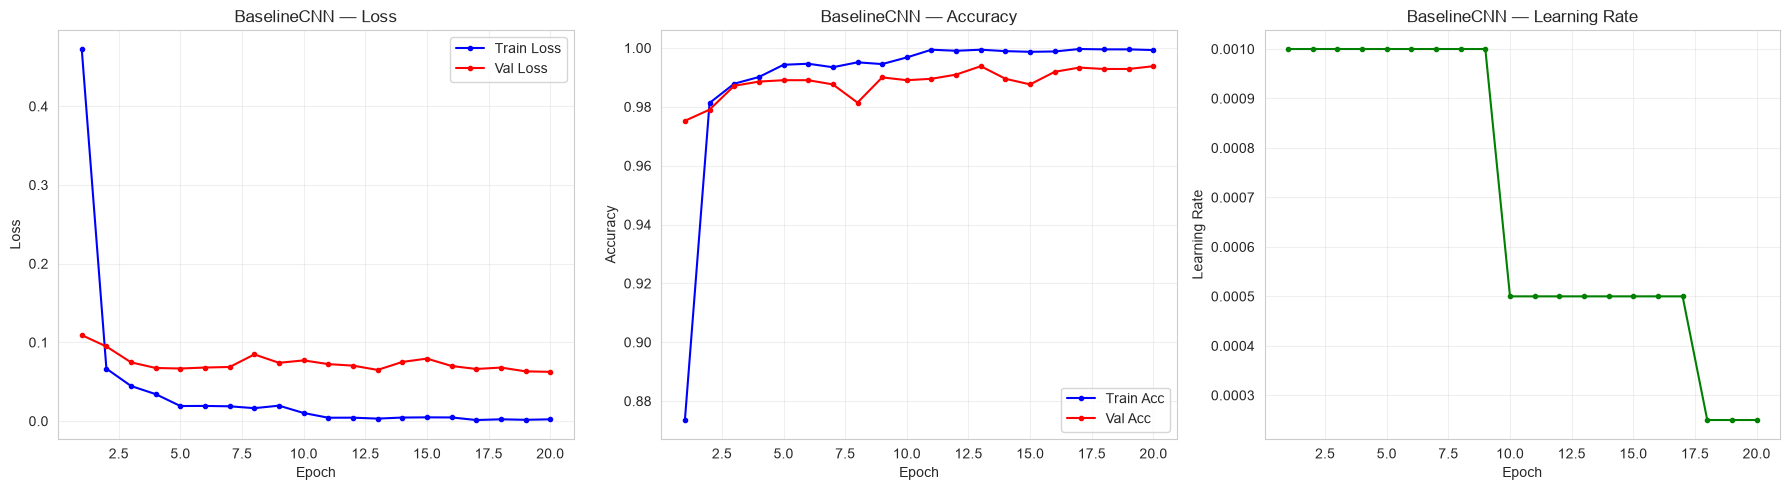

Grafik disimpan: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\outputs\figures\kurva_training_baselinecnn.png


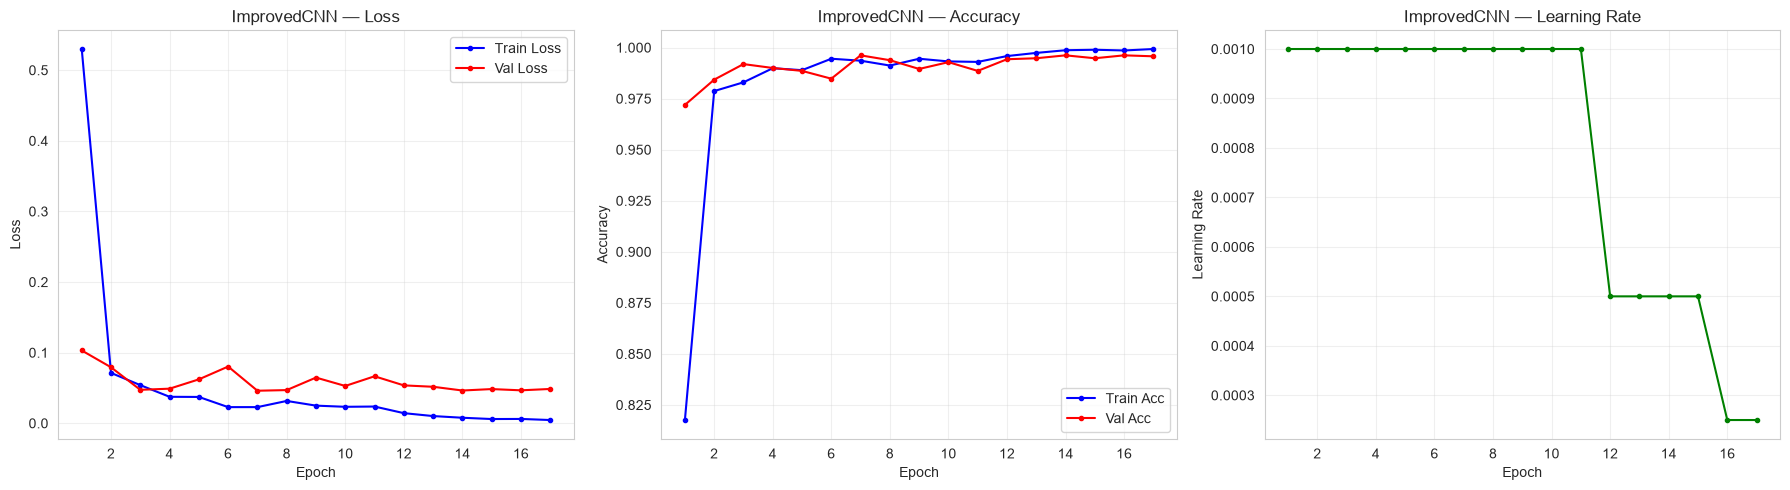

Grafik disimpan: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\outputs\figures\kurva_training_improvedcnn.png


In [13]:
def plot_training_curves(history, model_name, save_dir=FIGURES_DIR):
    """Membuat grafik kurva training loss, accuracy, dan learning rate."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    epochs = range(1, len(history['train_loss']) + 1)
    
    # Loss
    axes[0].plot(epochs, history['train_loss'], 'b-o', markersize=3, label='Train Loss')
    axes[0].plot(epochs, history['val_loss'], 'r-o', markersize=3, label='Val Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{model_name} — Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Accuracy
    axes[1].plot(epochs, history['train_acc'], 'b-o', markersize=3, label='Train Acc')
    axes[1].plot(epochs, history['val_acc'], 'r-o', markersize=3, label='Val Acc')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{model_name} — Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # Learning Rate
    axes[2].plot(epochs, history['lr'], 'g-o', markersize=3)
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Learning Rate')
    axes[2].set_title(f'{model_name} — Learning Rate')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    save_path = os.path.join(save_dir, f'kurva_training_{model_name.lower().replace(" ", "_")}.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Grafik disimpan: {save_path}")

# Plot untuk kedua model
plot_training_curves(baseline_history, 'BaselineCNN')
plot_training_curves(improved_history, 'ImprovedCNN')

## 8. Evaluasi Model Terbaik

Muat model terbaik dan evaluasi lengkap pada data validation.

In [14]:
# Tentukan model terbaik
print(f"Baseline best val acc: {baseline_best_acc:.4f}")
print(f"Improved best val acc: {improved_best_acc:.4f}")
print()

if improved_best_acc >= baseline_best_acc:
    best_model_name = "improved_cnn"
    best_model_class = ImprovedCNN
    best_model_kwargs = {'num_classes': NUM_CLASSES, 'dropout_rate': 0.4}
    print(f"→ Model terbaik: ImprovedCNN (val_acc={improved_best_acc:.4f})")
else:
    best_model_name = "baseline_cnn"
    best_model_class = BaselineCNN
    best_model_kwargs = {'num_classes': NUM_CLASSES}
    print(f"→ Model terbaik: BaselineCNN (val_acc={baseline_best_acc:.4f})")

Baseline best val acc: 0.9938
Improved best val acc: 0.9962

→ Model terbaik: ImprovedCNN (val_acc=0.9962)


In [15]:
# Muat model terbaik
best_checkpoint_path = os.path.join(MODELS_DIR, f"{best_model_name}_best.pth")
best_model = load_model(best_model_class, best_checkpoint_path, device, **best_model_kwargs)

# Evaluasi pada validation set
val_criterion = nn.CrossEntropyLoss()
val_loss, val_acc, val_preds, val_labels_actual = evaluate(
    best_model, val_loader, val_criterion, device
)

print(f"\nHasil evaluasi model terbaik ({best_model_name}):")
print(f"  Val Loss: {val_loss:.4f}")
print(f"  Val Accuracy: {val_acc:.4f} ({val_acc*100:.2f}%)")

Model dimuat dari: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\models\improved_cnn_best.pth
  Epoch: 7
  Val Acc: 0.9962
  Val Loss: 0.0460

Hasil evaluasi model terbaik (improved_cnn):
  Val Loss: 0.0460
  Val Accuracy: 0.9962 (99.62%)


### 8a. Confusion Matrix

c:\Users\TUF\OneDrive\Semester 5\ADM\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 38646 (\N{CJK UNIFIED IDEOGRAPH-96F6}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\TUF\OneDrive\Semester 5\ADM\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\TUF\OneDrive\Semester 5\ADM\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 20108 (\N{CJK UNIFIED IDEOGRAPH-4E8C}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\TUF\OneDrive\Semester 5\ADM\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 19977 (\N{CJK UNIFIED IDEOGRAPH-4E09}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\TUF\OneDrive\Semester 5\ADM\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 22235 (\N{CJK UNIFIED IDEOGRAPH-56DB}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\TUF\OneDrive\Semester 5\ADM\.venv\Lib\site-packages

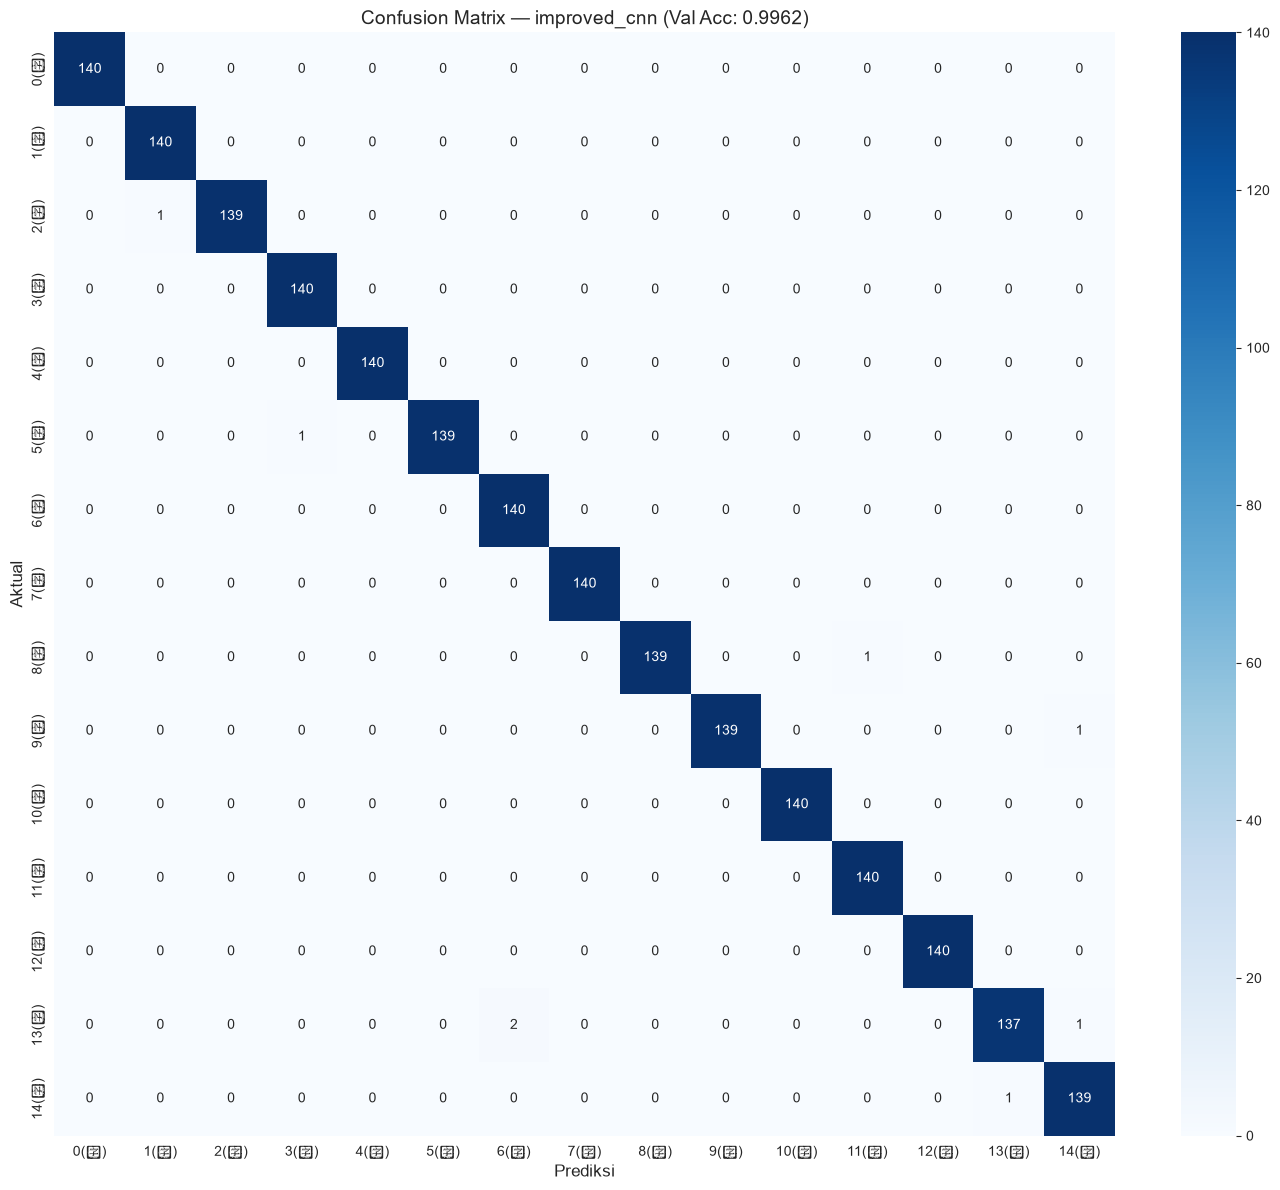

Grafik disimpan ke outputs/figures/confusion_matrix.png


In [16]:
# Confusion Matrix
cm = confusion_matrix(val_labels_actual, val_preds)

# Nama kelas untuk label
class_names = [f"{i}({label_to_char.get(i, '?')})" for i in range(NUM_CLASSES)]

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax)  # type: ignore

ax.set_xlabel('Prediksi', fontsize=12)
ax.set_ylabel('Aktual', fontsize=12)
ax.set_title(f'Confusion Matrix — {best_model_name} (Val Acc: {val_acc:.4f})', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan ke outputs/figures/confusion_matrix.png")

### 8b. Classification Report

In [17]:
# Classification Report
target_names = [f"Label {i} ({label_to_char.get(i, '?')})" for i in range(NUM_CLASSES)]
report = classification_report(
    val_labels_actual, val_preds,
    target_names=target_names,
    digits=4,
    zero_division=0
)
print("Classification Report:")
print(report)

# Simpan report ke file
report_path = os.path.join(METRICS_DIR, 'classification_report.txt')
with open(report_path, 'w', encoding='utf-8') as f:
    f.write(f"Model: {best_model_name}\n")
    f.write(f"Val Accuracy: {val_acc:.4f}\n")
    f.write(f"Val Loss: {val_loss:.4f}\n\n")
    f.write(str(report))
print(f"Report disimpan ke: {report_path}")

Classification Report:
              precision    recall  f1-score   support

 Label 0 (零)     1.0000    1.0000    1.0000       140
 Label 1 (一)     0.9929    1.0000    0.9964       140
 Label 2 (二)     1.0000    0.9929    0.9964       140
 Label 3 (三)     0.9929    1.0000    0.9964       140
 Label 4 (四)     1.0000    1.0000    1.0000       140
 Label 5 (五)     1.0000    0.9929    0.9964       140
 Label 6 (六)     0.9859    1.0000    0.9929       140
 Label 7 (七)     1.0000    1.0000    1.0000       140
 Label 8 (八)     1.0000    0.9929    0.9964       140
 Label 9 (九)     1.0000    0.9929    0.9964       140
Label 10 (十)     1.0000    1.0000    1.0000       140
Label 11 (百)     0.9929    1.0000    0.9964       140
Label 12 (千)     1.0000    1.0000    1.0000       140
Label 13 (万)     0.9928    0.9786    0.9856       140
Label 14 (亿)     0.9858    0.9929    0.9893       140

    accuracy                         0.9962      2100
   macro avg     0.9962    0.9962    0.9962      2100
wei

### 8c. Precision, Recall, F1 per Kelas

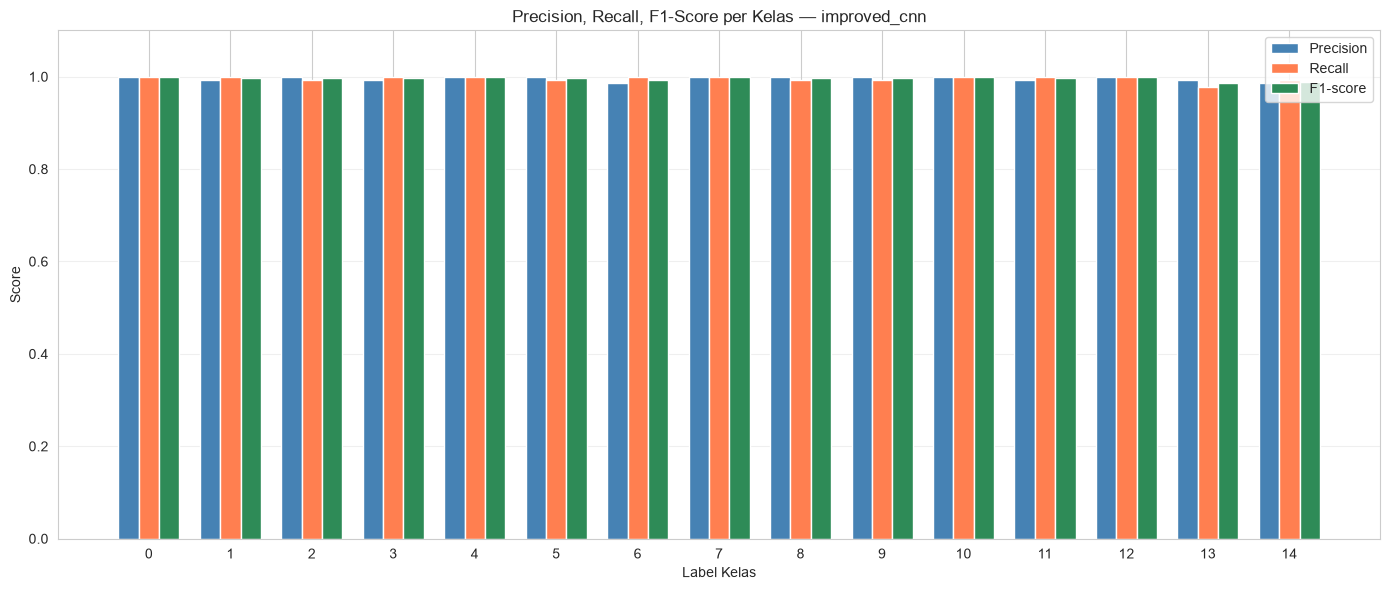

Grafik disimpan ke outputs/figures/precision_recall_f1.png


In [18]:
# Precision, Recall, F1 per kelas
precision, recall, f1, support = precision_recall_fscore_support(
    val_labels_actual, val_preds,
    average=None, zero_division=0
)
precision_arr = np.asarray(precision)
recall_arr = np.asarray(recall)
f1_arr = np.asarray(f1)

# Visualisasi
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(NUM_CLASSES)
width = 0.25

bars1 = ax.bar(x - width, precision_arr, width, label='Precision', color='steelblue')
bars2 = ax.bar(x, recall_arr, width, label='Recall', color='coral')
bars3 = ax.bar(x + width, f1_arr, width, label='F1-score', color='seagreen')

ax.set_xlabel('Label Kelas')
ax.set_ylabel('Score')
ax.set_title(f'Precision, Recall, F1-Score per Kelas — {best_model_name}')
ax.set_xticks(x)
ax.set_xticklabels([str(i) for i in range(NUM_CLASSES)])
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'precision_recall_f1.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Grafik disimpan ke outputs/figures/precision_recall_f1.png")

## 9. Simpan Metrik dan Konfigurasi

Menyimpan semua informasi yang diperlukan untuk reproduksi dan inference.

In [19]:
# Simpan metrik dan konfigurasi
metrics_summary = {
    "model_name": best_model_name,
    "checkpoint_path": best_checkpoint_path,
    "val_accuracy": float(val_acc),
    "val_loss": float(val_loss),
    "num_classes": NUM_CLASSES,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "random_seed": RANDOM_SEED,
    "split_method": "GroupShuffleSplit(test_size=0.2, by writer_id)",
    "num_train": len(X_train),
    "num_val": len(X_val),
    "num_train_writers": len(np.unique(writers_train)),
    "num_val_writers": len(np.unique(writers_val)),
    "preprocessing": "grayscale, normalize [0,1], shape (1,64,64)",
    "precision_per_class": {str(i): float(np.asarray(precision)[i]) for i in range(NUM_CLASSES)},
    "recall_per_class": {str(i): float(np.asarray(recall)[i]) for i in range(NUM_CLASSES)},
    "f1_per_class": {str(i): float(np.asarray(f1)[i]) for i in range(NUM_CLASSES)},
}


metrics_path = os.path.join(METRICS_DIR, 'metrics_summary.json')
with open(metrics_path, 'w', encoding='utf-8') as f:
    json.dump(metrics_summary, f, indent=2, ensure_ascii=False)
print(f"Metrik disimpan ke: {metrics_path}")

# Simpan konfigurasi inference (diperlukan oleh predict.py)
inference_config = {
    "model_class": best_model_name.replace('_cnn', '').capitalize() + 'CNN',
    "model_checkpoint": f"{best_model_name}_best.pth",
    "num_classes": NUM_CLASSES,
    "img_size": IMG_SIZE,
    "normalize": True,
    "label_to_character": {str(k): v for k, v in label_to_char.items()},
}

config_path = os.path.join(MODELS_DIR, 'inference_config.json')
with open(config_path, 'w', encoding='utf-8') as f:
    json.dump(inference_config, f, indent=2, ensure_ascii=False)
print(f"Konfigurasi inference disimpan ke: {config_path}")

Metrik disimpan ke: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\outputs\metrics\metrics_summary.json
Konfigurasi inference disimpan ke: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\models\inference_config.json


## 10. Verifikasi Model Tersimpan

Pastikan model bisa dimuat kembali dan menghasilkan prediksi.

In [20]:
# Verifikasi: muat kembali model dan prediksi beberapa gambar
print("Verifikasi model tersimpan...")
print()

# Muat ulang
test_model = load_model(best_model_class, best_checkpoint_path, device, **best_model_kwargs)

# Prediksi 5 gambar validation
test_model.eval()
sample_imgs_test = torch.from_numpy(
    X_val[:5].astype(np.float32) / 255.0
).unsqueeze(1).to(device)  # (5, 1, 64, 64)

with torch.no_grad():
    outputs = test_model(sample_imgs_test)
    preds = torch.argmax(outputs, dim=1).cpu().numpy()

print("\nHasil prediksi 5 gambar validation:")
for i in range(5):
    actual = y_val[i]
    pred = preds[i]
    status = "✓" if actual == pred else "✗"
    print(f"  {status} Aktual: {actual} ({label_to_char.get(actual, '?')}) | "
          f"Prediksi: {pred} ({label_to_char.get(pred, '?')})")

print("\n✓ Verifikasi selesai. Model dapat dimuat dan menghasilkan prediksi.")
print(f"\nCheckpoint terbaik: {best_checkpoint_path}")
print(f"Val Accuracy terbaik: {val_acc:.4f}")

Verifikasi model tersimpan...

Model dimuat dari: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\models\improved_cnn_best.pth
  Epoch: 7
  Val Acc: 0.9962
  Val Loss: 0.0460

Hasil prediksi 5 gambar validation:
  ✓ Aktual: 2 (二) | Prediksi: 2 (二)
  ✓ Aktual: 7 (七) | Prediksi: 7 (七)
  ✓ Aktual: 13 (万) | Prediksi: 13 (万)
  ✓ Aktual: 6 (六) | Prediksi: 6 (六)
  ✓ Aktual: 8 (八) | Prediksi: 8 (八)

✓ Verifikasi selesai. Model dapat dimuat dan menghasilkan prediksi.

Checkpoint terbaik: c:\Users\TUF\OneDrive\Semester 5\ADM\Final Project\models\improved_cnn_best.pth
Val Accuracy terbaik: 0.9962


## 11. Analisis Overfitting/Underfitting

Berdasarkan kurva training di atas, kita analisis apakah model mengalami masalah.

In [21]:
# Perbandingan ringkas kedua model
print("=" * 60)
print("RINGKASAN EKSPERIMEN")
print("=" * 60)

for name, history, best_acc in [
    ("BaselineCNN", baseline_history, baseline_best_acc),
    ("ImprovedCNN", improved_history, improved_best_acc)
]:
    final_train_acc = history['train_acc'][-1]
    final_val_acc = history['val_acc'][-1]
    gap = final_train_acc - final_val_acc
    
    print(f"\n{name}:")
    print(f"  Epochs: {len(history['train_loss'])}")
    print(f"  Best Val Acc: {best_acc:.4f}")
    print(f"  Final Train Acc: {final_train_acc:.4f}")
    print(f"  Final Val Acc: {final_val_acc:.4f}")
    print(f"  Gap (train - val): {gap:.4f}")
    
    if gap > 0.15:
        print(f"  Kemungkinan overfitting (gap > 0.15)")
    elif final_val_acc < 0.5:
        print(f"  Kemungkinan underfitting (val acc < 0.5)")
    else:
        print(f"  Model tampak baik")

print(f"Model terpilih: {best_model_name}")
print(f"Lanjut ke notebook 03_prediction_submission.ipynb")

RINGKASAN EKSPERIMEN

BaselineCNN:
  Epochs: 20
  Best Val Acc: 0.9938
  Final Train Acc: 0.9993
  Final Val Acc: 0.9938
  Gap (train - val): 0.0055
  Model tampak baik

ImprovedCNN:
  Epochs: 17
  Best Val Acc: 0.9962
  Final Train Acc: 0.9993
  Final Val Acc: 0.9957
  Gap (train - val): 0.0036
  Model tampak baik
Model terpilih: improved_cnn
Lanjut ke notebook 03_prediction_submission.ipynb
